<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/var-es-sp500/10_stress_tests.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 10 - Stress tests

09 showed that the VaR of the risk-parity portfolios relies on the hedges (gold, bonds) working. Two classic stress tests to look at what happens when they don't:
1. historical scenarios: the asset moves of past crises applied to today's weights
2. correlation stress: today's volatilities with the stock / hedge correlations of the old regime, of today, and of a crisis

Takes ~1 min.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/var-es-sp500
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from risk import *
plt.style.use("quant.mplstyle")

assets = ["spx", "aapl", "msft", "jpm", "xom", "gld", "tlt"]
prices = pd.concat({a: load_close("../black-scholes-sp500/data/sp500.csv" if a == "spx" else f"data/{a}.csv") for a in assets},
                   axis=1).dropna()
rets = np.log(prices).diff().dropna()
simple = np.exp(rets) - 1

weights = {"S&P 500": np.eye(7)[0], "1/7": np.full(7, 1 / 7),
           "yearly ES": rolling_equal_risk_weights(simple).iloc[-1].values,
           "monthly DCC": monthly_risk_parity(rets, "dcc").iloc[-1].values}
print("weights today (" + str(prices.index[-1].date()) + "):")
print(pd.DataFrame(weights, index=assets).T.round(3))
# yearly ES has 58% in gold + bonds today, monthly DCC 38% and more energy (XOM 18%)

weights today (2026-11-19):
               spx   aapl   msft    jpm    xom    gld    tlt
S&P 500      1.000  0.000  0.000  0.000  0.000  0.000  0.000
1/7          0.143  0.143  0.143  0.143  0.143  0.143  0.143
yearly ES    0.087  0.068  0.081  0.093  0.090  0.269  0.312
monthly DCC  0.134  0.111  0.104  0.094  0.179  0.096  0.283


In [3]:
scenarios = {"Lehman": ("2008-09-15", "2008-10-15"), "Covid crash": ("2020-02-19", "2020-03-23"),
             "dash for cash": ("2020-03-09", "2020-03-18"), "2022 inflation": ("2022-01-03", "2022-10-14")}

def move(a, b):
    # buy-and-hold return of each asset from the close before day a to the close of day b
    i = prices.index.get_indexer([pd.Timestamp(a)], method="bfill")[0]
    return prices.loc[b] / prices.iloc[i - 1] - 1

moves = pd.DataFrame({nm: move(a, b) for nm, (a, b) in scenarios.items()}).T
print("asset moves (%):")
print((100 * moves).round(1))
losses = pd.DataFrame({p: moves.values @ w for p, w in weights.items()}, index=moves.index)
print()
print("portfolio with today's weights (%):")
print((100 * losses).round(1))

asset moves (%):
                 spx  aapl  msft   jpm   xom   gld   tlt
Lehman         -27.5 -34.2 -18.0  -5.8 -19.5  10.3   0.4
Covid crash    -33.6 -29.7 -27.2 -41.7 -47.5  -3.1  14.2
dash for cash  -19.3 -14.7 -13.1 -22.4 -30.6 -10.7 -13.4
2022 inflation -24.8 -21.7 -31.6 -27.6  67.2 -10.5 -32.4

portfolio with today's weights (%):
                S&P 500   1/7  yearly ES  monthly DCC
Lehman            -27.5 -13.5       -5.6        -12.3
Covid crash       -33.6 -24.1      -11.7        -19.3
dash for cash     -19.3 -17.7      -15.6        -18.0
2022 inflation    -24.8 -11.6      -15.6         -9.7


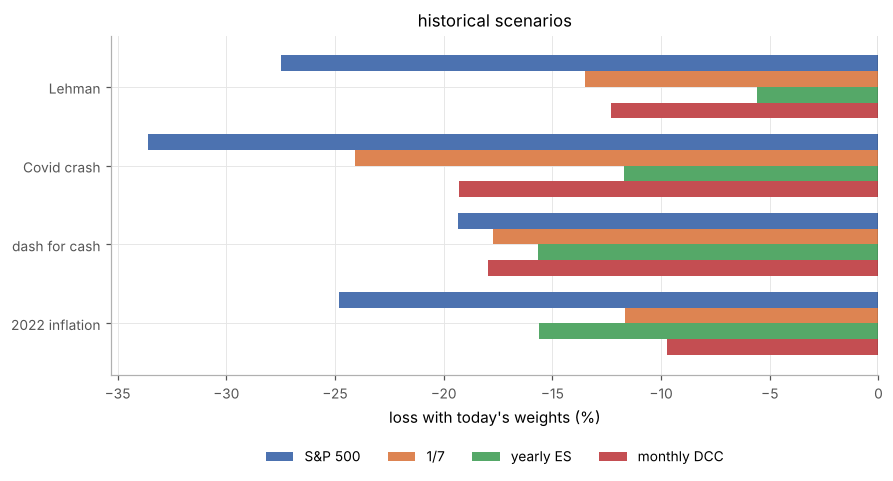

In [4]:
ax = (100 * losses).plot.barh(figsize=(9, 4), width=0.8)
ax.invert_yaxis(); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("loss with today's weights (%)"); ax.set_title("historical scenarios")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.show()
# Lehman and the covid crash: the hedges worked (bonds flat or +14%, gold +10% in 2008), the risk-parity
# portfolios lose 2-5 times less than the S&P (yearly ES -5.6% vs -27.5% for Lehman)
# dash for cash: gold -11% and bonds -13% with the stocks, everybody loses 15.6-19.3%, diversification gone in 8 days
# 2022: bonds -32%, gold -10%. the yearly ES portfolio loses more than plain 1/7 (-15.6% vs -11.6%)
# monthly DCC does best in 2022 (-9.7%), helped by its 18% in Exxon (+67% that year)

In [5]:
# correlation stress: today's vols (last 250 days), three correlation states between the 5 stocks and gold / bonds
vol = rets.iloc[-250:].std().values
C_now = rets.iloc[-250:].corr().values
C_old = rets.loc["2009":"2021"].corr().values
stocks, hedges = range(5), [5, 6]
C_old_hedge = C_now.copy()                      # today's matrix, but the stock / hedge block of 2009-2021
C_old_hedge[np.ix_(stocks, hedges)] = C_old[np.ix_(stocks, hedges)]
C_old_hedge[np.ix_(hedges, stocks)] = C_old[np.ix_(hedges, stocks)]
C_old_hedge = stress_correlation(C_old_hedge, [], [], 0)   # only to make sure it is a valid matrix
states = {"old regime (2009-21)": C_old_hedge, "today": C_now, "crisis (+0.6)": stress_correlation(C_now, stocks, hedges, 0.6)}
print("average correlation stocks / bonds, stocks / gold:")
for s, C in states.items():
    print(f"  {s:22s} {C[np.ix_(stocks, [6])].mean():+.2f}  {C[np.ix_(stocks, [5])].mean():+.2f}")

z = stats.norm.ppf(0.99)
var1 = pd.DataFrame({s: {p: z * np.sqrt(w @ (C * np.outer(vol, vol)) @ w) for p, w in weights.items()} for s, C in states.items()})
print()
print("1-day VaR 99% (normal, %):")
print((100 * var1).round(2))
print()
print("ratio to the old regime:")
print((var1.div(var1.iloc[:, 0], axis=0)).round(2))
# the +0.6 asked for ends at +0.44 on average: the matrix has to stay a valid correlation matrix
# the risk-parity weights were sized when bonds were at -0.35 with stocks: with today's correlation (+0.04)
# the same portfolios are 1.17-1.31x as risky, in the crisis state 1.52-1.85x (monthly DCC the most, it leans
# the most on the bonds being a hedge). the S&P alone doesn't move, it has no hedge
# normal VaR here, only to compare the states with each other: the tails are thicker than that (02)

average correlation stocks / bonds, stocks / gold:
  old regime (2009-21)   -0.35  +0.01
  today                  +0.04  +0.15
  crisis (+0.6)          +0.44  +0.44

1-day VaR 99% (normal, %):
             old regime (2009-21)  today  crisis (+0.6)
S&P 500                      2.03   2.03           2.03
1/7                          1.39   1.62           2.11
yearly ES                    1.36   1.65           2.15
monthly DCC                  1.01   1.31           1.86

ratio to the old regime:
             old regime (2009-21)  today  crisis (+0.6)
S&P 500                       1.0   1.00           1.00
1/7                           1.0   1.17           1.52
yearly ES                     1.0   1.21           1.58
monthly DCC                   1.0   1.31           1.85


In [6]:
# does the 10-day VaR in the crisis state cover the dash for cash, which lasted 8 trading days?
var10 = var1 * np.sqrt(10)
check = pd.DataFrame({"10-day VaR, today": 100 * var10["today"], "10-day VaR, crisis": 100 * var10["crisis (+0.6)"],
                      "dash for cash loss": -100 * losses.loc["dash for cash"]}).round(1)
print(check)
# even the crisis-correlation VaR stays well below the dash-for-cash loss for every portfolio (6-7% vs 16-19%):
# in march 2020 the vols of the stocks and bonds were 4.6-9.3 times today's (gold unchanged), not only the
# correlations. a stress test has to move both at once, a VaR fitted on calm data can't see it coming

             10-day VaR, today  10-day VaR, crisis  dash for cash loss
S&P 500                    6.4                 6.4                19.3
1/7                        5.1                 6.7                17.7
yearly ES                  5.2                 6.8                15.6
monthly DCC                4.1                 5.9                18.0
